**1. Import Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import gutenberg
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.utils import to_categorical

In [ ]:
nltk.download('gutenberg')

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!


True

In [ ]:
# Load Hamlet dataset
data = gutenberg.raw('shakespeare-hamlet.txt')

# Total words
words = data.split()
print("Total words:", len(words))

# Sample text
print("\nSample Text:\n")
print('\n'.join(data.split('\n')[:10]))

Total words: 29605

Sample Text:

[The Tragedie of Hamlet by William Shakespeare 1599]


Actus Primus. Scoena Prima.

Enter Barnardo and Francisco two Centinels.

  Barnardo. Who's there?
  Fran. Nay answer me: Stand & vnfold
your selfe


In [ ]:
# Lowercase
data = data.lower()

# Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])

total_words = len(tokenizer.word_index) + 1
print("Total unique words:", total_words)

Total unique words: 4818


In [ ]:
input_sequences = []

for line in data.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]

    for i in range(1, len(token_list)):
        n_gram_seq = token_list[:i+1]
        input_sequences.append(n_gram_seq)

print("Total sequences:", len(input_sequences))

Total sequences: 25732


In [ ]:
max_seq_len = max([len(seq) for seq in input_sequences])

input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding='pre')

X = input_sequences[:, :-1]
y = input_sequences[:, -1]

y = to_categorical(y, num_classes=total_words)

In [ ]:
model = Sequential()

model.add(Embedding(input_dim=total_words, output_dim=100, input_shape=(max_seq_len-1,)))
model.add(LSTM(250))
model.add(Dropout(0.4))
model.add(Dense(total_words, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ (None, 13, 100)        │       481,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 250)            │       351,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 4818)           │     1,209,318 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,042,118 (7.79 MB)

 Trainable params: 2,042,118 (7.79 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X, y,
    epochs=50,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0426 - loss: 6.3627 - val_accuracy: 0.0482 - val_loss: 7.0962
Epoch 2/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0525 - loss: 6.1739 - val_accuracy: 0.0509 - val_loss: 7.2386
Epoch 3/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.0581 - loss: 6.0268 - val_accuracy: 0.0534 - val_loss: 7.3072
Epoch 4/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.0697 - loss: 5.8563 - val_accuracy: 0.0575 - val_loss: 7.4005
Epoch 5/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.0805 - loss: 5.6421 - val_accuracy: 0.0624 - val_loss: 7.4783
Epoch 6/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.0917 - loss: 5.4049 - val_accuracy: 0.0649 - val_loss: 7.6714
Epoch 7/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.1029 - loss: 5.1714 - val_accuracy: 0.0618 - val_loss: 7.7513
Epoch 8/50
644/644 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.1143 - loss: 4.9106 - val_accuracy: 

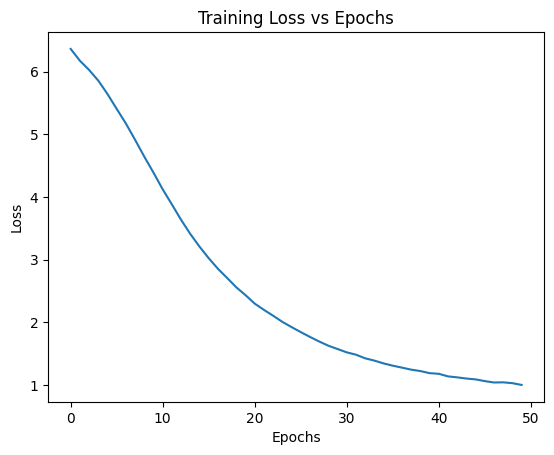

In [ ]:
plt.plot(history.history['loss'])
plt.title("Training Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()

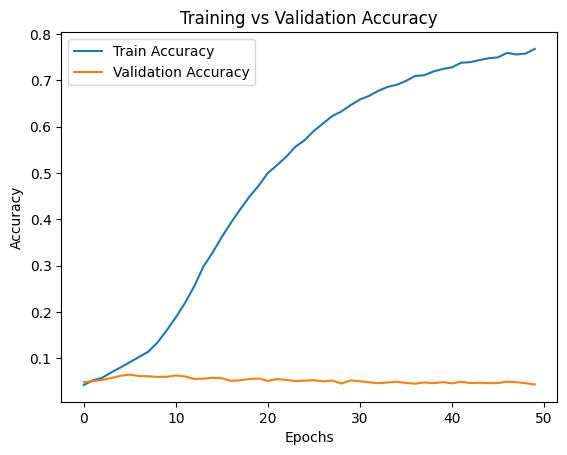

In [ ]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend(['Train Accuracy', 'Validation Accuracy'])
plt.show()

In [ ]:
def predict_next_word(seed_text, next_words=1):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len-1, padding='pre')

        predicted = np.argmax(model.predict(token_list), axis=-1)

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break

        seed_text += " " + output_word

    return seed_text

In [ ]:
print(predict_next_word("to be or not"))
print(predict_next_word("the king is"))
print(predict_next_word("i am"))
print(predict_next_word("what is"))
print(predict_next_word("he shall"))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
to be or not to
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
the king is not
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step
i am sorrie
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
what is betweene
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
he shall approue
